In [1]:
import numpy as np
import matplotlib.pyplot as plt

La primera ley de Fick es
$$ J=-D\frac{\partial C}{\partial x}$$

$D$ es un parametro que determina la rapidez con la que el $CO_2$ se difunde en el líquido.

- $L$: espesor del líquido (mm)
- $\Delta t$: paso temporal (s)
- $\Delta x$: distancia espacil $(\mu m)$
- `t_final`: tiempo simulado (s)
- $k$: constante de consumo superficial (m/s)

$$r = D \frac{\Delta t}{(\Delta x)^2}$$

In [2]:


L = 1e-3
D = 1.9e-9
k = 1e-4
C_bulk = 33.0  # Concentración exterior

N = 50  # Número de intervalos
dx = L / N

dt = 0.1
t_final = 10
n_steps = int(t_final / dt)

r = D * dt / dx**2

print(f"dx = {dx:.3e} m")
print(f"r = {r:.4f}")

dx = 2.000e-05 m
r = 0.4750


Suponemos que la cantidad de $CO_2$ que consume el electrodo por unidad de área y por unididad de tiempo es igual ala concentración de $CO_2$ justo en la superficie $(C_s)$ del electrodo multiplicada por un factor de proporcionalidad $k$ que dice qué tan ráido consume el electrodo el $CO_2$ disponible.

$$ J_{consumo} = kC_s $$

---

Como tenemos concentraciones en dos posiciones, podemos aproximar la derivada

$$\frac{\partial C}{\partial x}\approx \frac{C_1-C_0}{\Delta x}$$

Y al sustituir la primera ley de Fick $(J=-D\partial C/\partial x)$ queda

$$ J\approx -D\frac{C_1-C_0}{\Delta x}$$

---

Suponemos que no hay acomulción de $CO_2$ en la superficie, entonces el fllujo que llega por difusión debe ser igual al consumo:

$$ J_{dif}=J_{consumo} $$

Sustituyendo

$$D\frac{C_1-C_0}{\Delta x}=kC_0$$

De aquí podemos despejar $C_0$

$$ C_0 = \frac{D}{D+k\Delta x}C_1$$

In [3]:
x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt

C = np.full(N + 1, C_bulk)

alpha = D / (D + k * dx)

C[0] = alpha * C[1]
C[-1] = C_bulk

$C$ contiene la concentración en todos los puntos en un instante. a medida que avanza el tiempo las concentraciones cambian, entonces necesitamos guardar una copia de $C$ en cada instante.

Creamos una matriz de ceros con dimension (número de instantes temporales que vamos a guardar INCLUIDO EL INICIAL)$\times$ (número de puntos iniciales donde calculamos la concentración)

El `C.copy` va guardando el perfil de concentración en la fila $n$ de la matriz

In [4]:
C_history = np.zeros((n_steps + 1, N + 1))
C_history[0] = C.copy()

La segunda ley de Fick es
$$ \frac{\partial C}{\partial t}=D\frac{\partial^2 C}{\partial x^2}$$

Con un desarrollo que esta en el notion llegamos a 

$$C_i^{n+1}=C_i^{n}+r(C_{i+1}^n-2C_i^n+C_{i-1}^n)$$

- `C[1:N]` es la concentración actual $(C_i^n)$
- `C[2:N+1]` es la concentración del vecino a la derecha $(C_{i+1}^n)$
- `C[0:N-1]` concentración del vecino izquierdo $(C_{i-1}^n)$
- `r` es $D\, \Delta t / (\Delta x)^2$
- `C_new[1:N]` es la concentración en el instante siguiente $(C_i^{n+1})$ 

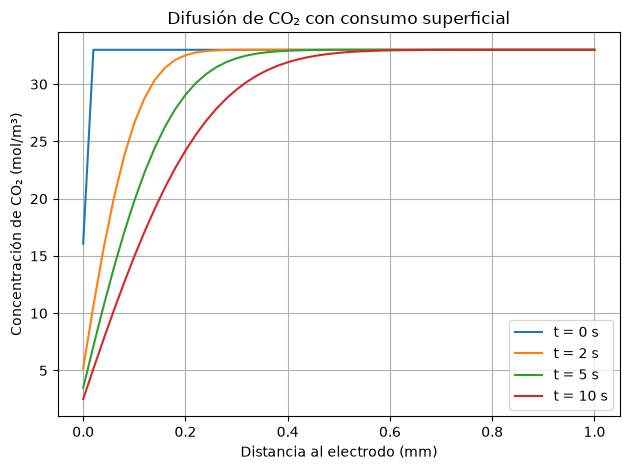

In [5]:
for n in range(n_steps):

    C_new = C.copy()

    C_new[1:N] = C[1:N] + r * (
        C[2:N+1] - 2*C[1:N] + C[0:N-1]
    )

    C_new[0] = alpha * C_new[1]

    C_new[-1] = C_bulk

    # avanzar al siguiente instante
    C = C_new
    C_history[n + 1] = C.copy()

# 7. Graficar perfiles de concentración
for tiempo in [0, 2, 5, 10]:
    indice = int(tiempo / dt)
    plt.plot(
        x * 1e3,
        C_history[indice],
        label=f"t = {tiempo} s"
    )

plt.xlabel("Distancia al electrodo (mm)")
plt.ylabel("Concentración de CO₂ (mol/m³)")
plt.title("Difusión de CO₂ con consumo superficial")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

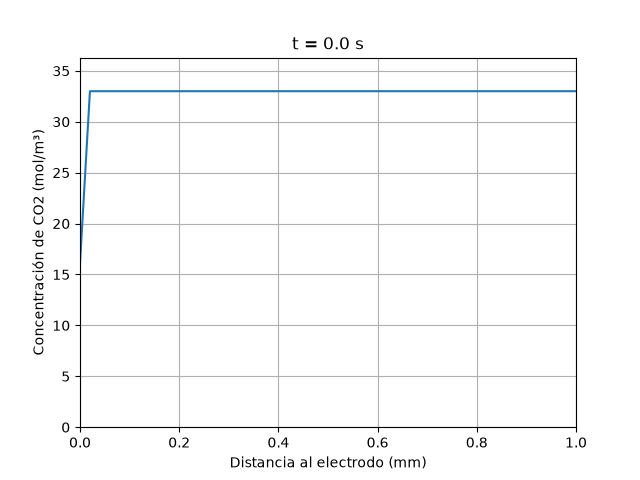

In [6]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fig, ax = plt.subplots()

line, = ax.plot(x * 1e3, C_history[0])

ax.set_xlim(0, L * 1e3)
ax.set_ylim(0, C_bulk * 1.1)
ax.set_xlabel("Distancia al electrodo (mm)")
ax.set_ylabel("Concentración de CO2 (mol/m³)")
ax.grid()

title = ax.set_title("t = 0 s")

def update(n):
    line.set_ydata(C_history[n])
    title.set_text(f"t = {t[n]:.1f} s")
    return line, title

ani = FuncAnimation(
    fig, update,
    frames=len(t),
    interval=100
)

ani.save("difusion.gif", writer=PillowWriter(fps=10))
plt.close()

display(Image(filename="difusion.gif"))

Suponemos que el volumen de la mezcla no cambia significativamente

$$ \rho(C)= \rho_{bulk}+\beta(C-C_{bulk}) $$

$\beta$ mide cuánto cambia la densidad cuando cambia la concentración.

---

Tenemos la siguiente relación

$$ D(\rho)=D_0\bigg(\frac{\rho_{bulk}}{\rho}\bigg)^m $$

- $D_0$: difusividad de referencia
- $\rho_{bulk}$: densidad de referencia
- $m$: sensibilidad de $D_0$ respecto a $\rho$.

Como el electrodo consume $CO_2$, cerca de él $C<C_{bulk}$, entonces $\rho<\rho_{bulk}$: la densidad es menor junto al electrodo y aumenta hacia el seno del líquido.

Al depender $D$ de la posición, la segunda ley de Fick queda

$$ \frac{\partial C}{\partial t}=\frac{\partial}{\partial x}\bigg(D(\rho)\frac{\partial C}{\partial x}\bigg)$$

Evaluando $D$ entre nodos, $D_{i\pm 1/2}=\frac{D_i+D_{i\pm1}}{2}$, la discretización es

$$C_i^{n+1}=C_i^{n}+\frac{\Delta t}{(\Delta x)^2}\Big[D_{i+1/2}(C_{i+1}^n-C_i^n)-D_{i-1/2}(C_i^n-C_{i-1}^n)\Big]$$

En el electrodo se usa la misma condición de antes con la difusividad local:

$$ C_0 = \frac{D_0^{s}}{D_0^{s}+k\Delta x}C_1, \qquad D_0^{s}=D(\rho(C_0))$$

Con $m=0$ se recupera el modelo de solo difusión.

r máximo = 0.2715
rho en el electrodo (t = 10.0 s) = 998.664 kg/m³
rho en el bulk = 1000.000 kg/m³


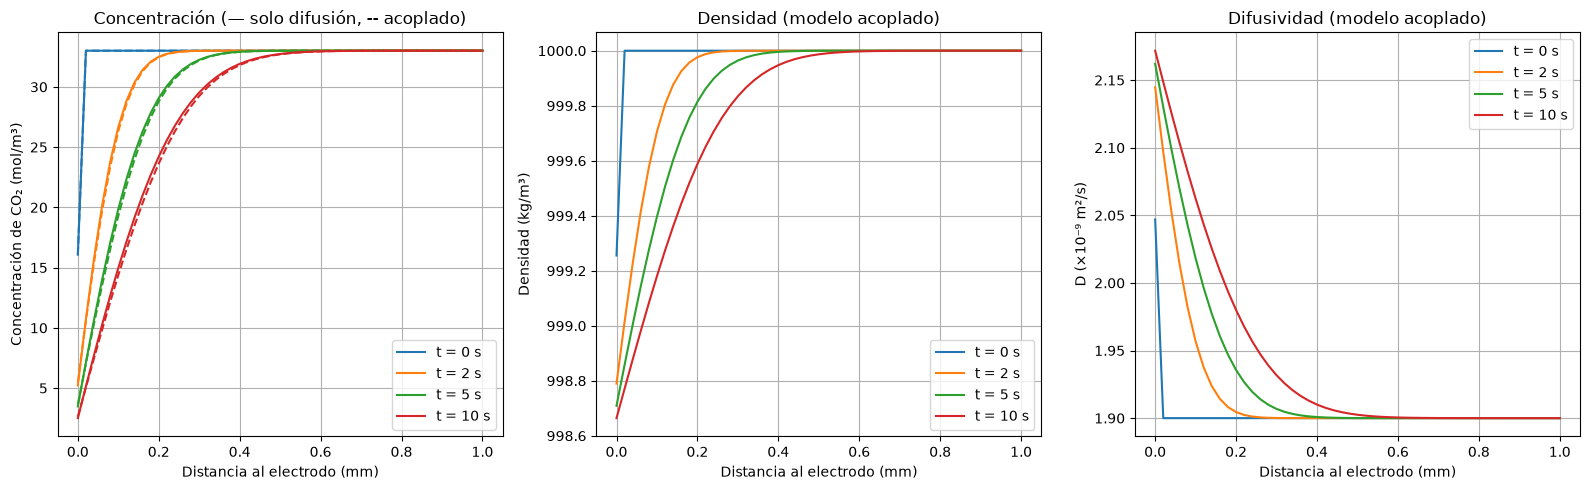

In [7]:
L = 1e-3
D_0 = 1.9e-9
k = 1e-4
C_bulk = 33.0
rho_bulk = 1000.0
beta = 0.044
m = 100

N = 50
dx = L / N
dt = 0.05
t_final = 10.0
n_steps = int(t_final / dt)

x = [i * dx for i in range(N + 1)]
t = [n * dt for n in range(n_steps + 1)]


def densidad(c):
    return rho_bulk + beta * (c - C_bulk)


def difusividad(rho, m):
    return D_0 * (rho_bulk / rho) ** m


def simular(m):
    C = [C_bulk] * (N + 1)
    C[0] = D_0 / (D_0 + k * dx) * C[1]

    rho = [densidad(c) for c in C]
    D = [difusividad(p, m) for p in rho]
    historia_C = [C[:]]
    historia_rho = [rho]
    historia_D = [D]

    for n in range(n_steps):
        C_new = C[:]
        for i in range(1, N):
            D_der = (D[i] + D[i + 1]) / 2
            D_izq = (D[i - 1] + D[i]) / 2
            C_new[i] = C[i] + dt / dx**2 * (
                D_der * (C[i + 1] - C[i]) - D_izq * (C[i] - C[i - 1])
            )
        C_new[0] = D[0] / (D[0] + k * dx) * C_new[1]
        C_new[-1] = C_bulk
        C = C_new

        rho = [densidad(c) for c in C]
        D = [difusividad(p, m) for p in rho]
        historia_C.append(C[:])
        historia_rho.append(rho)
        historia_D.append(D)

    return historia_C, historia_rho, historia_D


C_hist_dif, rho_hist_dif, D_hist_dif = simular(0)
C_hist, rho_hist, D_hist = simular(m)

r_max = max(max(fila) for fila in D_hist) * dt / dx**2
print(f"r máximo = {r_max:.4f}")
print(f"rho en el electrodo (t = {t_final} s) = {rho_hist[-1][0]:.3f} kg/m³")
print(f"rho en el bulk = {rho_hist[-1][-1]:.3f} kg/m³")

x_mm = [xi * 1e3 for xi in x]
tiempos = [0, 2, 5, 10]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for tiempo in tiempos:
    n = round(tiempo / dt)
    linea, = axes[0].plot(x_mm, C_hist_dif[n], label=f"t = {tiempo} s")
    axes[0].plot(x_mm, C_hist[n], "--", color=linea.get_color())
    axes[1].plot(x_mm, rho_hist[n], label=f"t = {tiempo} s")
    axes[2].plot(x_mm, [d * 1e9 for d in D_hist[n]], label=f"t = {tiempo} s")

axes[0].set_title("Concentración (— solo difusión, -- acoplado)")
axes[0].set_ylabel("Concentración de CO₂ (mol/m³)")
axes[1].set_title("Densidad (modelo acoplado)")
axes[1].set_ylabel("Densidad (kg/m³)")
axes[2].set_title("Difusividad (modelo acoplado)")
axes[2].set_ylabel("D (×10⁻⁹ m²/s)")

for ax in axes:
    ax.set_xlabel("Distancia al electrodo (mm)")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

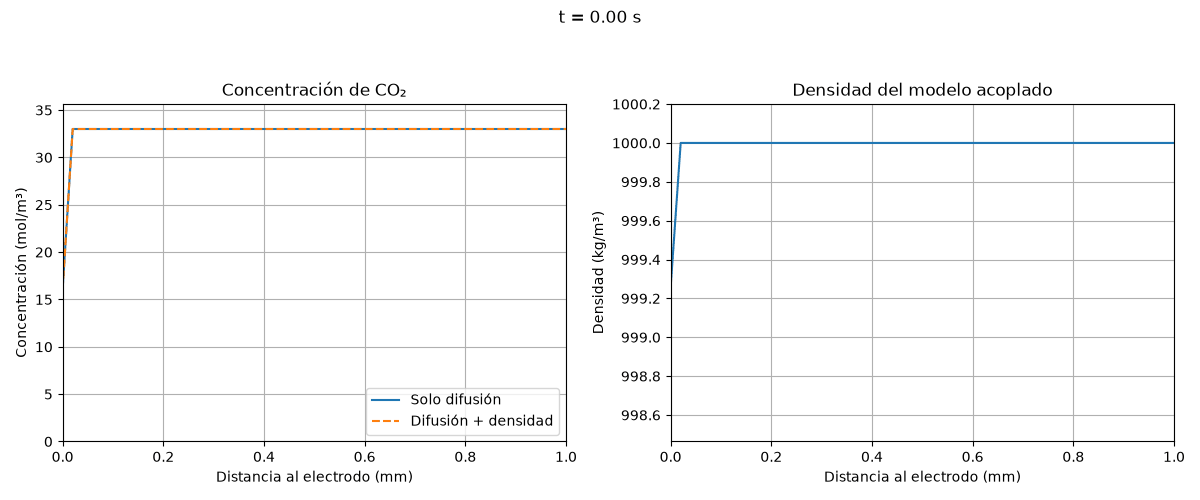

In [8]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

rho_min = min(min(fila) for fila in rho_hist)
rho_max = max(max(fila) for fila in rho_hist)
rho_pad = max((rho_max - rho_min) * 0.15, 0.002)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=100)

line_dif, = axes[0].plot(x_mm, C_hist_dif[0], label="Solo difusión")
line_acop, = axes[0].plot(x_mm, C_hist[0], "--", label="Difusión + densidad")
axes[0].set_title("Concentración de CO₂")
axes[0].set_xlabel("Distancia al electrodo (mm)")
axes[0].set_ylabel("Concentración (mol/m³)")
axes[0].set_xlim(0, L * 1e3)
axes[0].set_ylim(0, C_bulk * 1.08)
axes[0].grid(True)
axes[0].legend(loc="lower right")

line_rho, = axes[1].plot(x_mm, rho_hist[0])
axes[1].set_title("Densidad del modelo acoplado")
axes[1].set_xlabel("Distancia al electrodo (mm)")
axes[1].set_ylabel("Densidad (kg/m³)")
axes[1].set_xlim(0, L * 1e3)
axes[1].set_ylim(rho_min - rho_pad, rho_max + rho_pad)
axes[1].grid(True)

titulo = fig.suptitle("t = 0.00 s")
fig.tight_layout(rect=[0, 0, 1, 0.93])


def update(n):
    line_dif.set_ydata(C_hist_dif[n])
    line_acop.set_ydata(C_hist[n])
    line_rho.set_ydata(rho_hist[n])
    titulo.set_text(f"t = {t[n]:.2f} s")
    return line_dif, line_acop, line_rho, titulo


ani = FuncAnimation(fig, update, frames=len(t), interval=50)

gif_path = "difusion_densidad_acoplada.gif"
ani.save(gif_path, writer=PillowWriter(fps=20))
plt.close(fig)

display(Image(filename=gif_path))

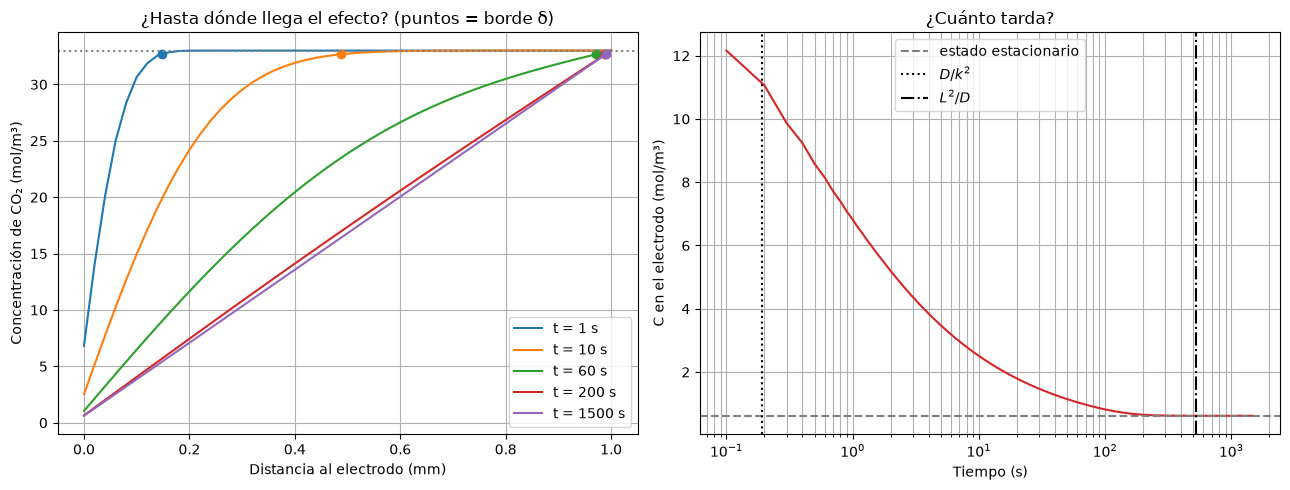

D/k^2 = 0.19 s   |   L^2/D = 526 s
C en el electrodo, estado estacionario = 0.615 mol/m³


In [9]:
dt2 = 0.1         
t_final2 = 1500  
n_steps2 = int(t_final2 / dt2)
r2 = D * dt2 / dx**2

x = np.linspace(0, L, N + 1)
t2 = np.arange(n_steps2 + 1) * dt2

C = np.full(N + 1, C_bulk)
C[0] = alpha * C[1]

C_hist2 = np.zeros((n_steps2 + 1, N + 1))
C_hist2[0] = C.copy()

for n in range(n_steps2):
    C_new = C.copy()
    C_new[1:N] = C[1:N] + r2 * (C[2:N+1] - 2*C[1:N] + C[0:N-1])
    C_new[0] = alpha * C_new[1]
    C_new[-1] = C_bulk
    C = C_new
    C_hist2[n + 1] = C.copy()


def grosor_capa(perfil, umbral=0.99):
    """Distancia donde la concentración llega al 99 % de C_bulk (borde de la capa límite)."""
    dentro = perfil >= umbral * C_bulk
    i = np.argmax(dentro)
    if i == 0:
        return 0.0
    return np.interp(umbral * C_bulk, [perfil[i-1], perfil[i]], [x[i-1], x[i]])


C_s = C_hist2[:, 0]
C_s_final = C_bulk / (1 + k * L / D)

# --------------------- Gráficas ---------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pregunta 1: perfiles y borde de la capa límite
for tiempo in [1, 10, 60, 200, 1500]:
    n = round(tiempo / dt2)
    linea, = axes[0].plot(x * 1e3, C_hist2[n], label=f"t = {tiempo} s")
    delta = grosor_capa(C_hist2[n])
    axes[0].plot(delta * 1e3, 0.99 * C_bulk, "o", color=linea.get_color())

axes[0].axhline(C_bulk, color="gray", ls=":")
axes[0].set_xlabel("Distancia al electrodo (mm)")
axes[0].set_ylabel("Concentración de CO₂ (mol/m³)")
axes[0].set_title("¿Hasta dónde llega el efecto? (puntos = borde δ)")
axes[0].legend()
axes[0].grid(True)

# Pregunta 2: concentración en el electrodo vs tiempo
axes[1].semilogx(t2[1:], C_s[1:], color="C3")
axes[1].axhline(C_s_final, color="gray", ls="--", label="estado estacionario")
axes[1].axvline(D / k**2, color="k", ls=":", label=r"$D/k^2$")
axes[1].axvline(L**2 / D, color="k", ls="-.", label=r"$L^2/D$")
axes[1].set_xlabel("Tiempo (s)")
axes[1].set_ylabel("C en el electrodo (mol/m³)")
axes[1].set_title("¿Cuánto tarda?")
axes[1].legend()
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

print(f"D/k^2 = {D/k**2:.2f} s   |   L^2/D = {L**2/D:.0f} s")
print(f"C en el electrodo, estado estacionario = {C_s_final:.3f} mol/m³")